In [33]:
#importing the necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as pt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [34]:
#importing the dataset
df=pd.read_csv('OMIS1.csv')
df.head()

,Year of Experience,Salaries
0,3.0,5000
1,5.0,6500
2,6.0,7200
3,4.0,5800
4,10.0,10700


In [35]:
df    #dataset

,Year of Experience,Salaries
0,3.0,5000
1,5.0,6500
2,6.0,7200
3,4.0,5800
4,10.0,10700
5,8.0,8600
6,6.0,7350
7,4.0,5900
8,3.0,4950
9,9.0,9100


In [36]:
#dataset dimension
df.shape

(17, 2)

In [37]:
#names and datatypes of the columns
df.columns


Index(['Year of Experience ', 'Salaries'], dtype='object')

In [38]:
##number , datatype and memory usage of columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17 entries, 0 to 16
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year of Experience   17 non-null     float64
 1   Salaries             17 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 404.0 bytes


In [39]:
#statistical summary of the continous variables only
df.describe()

,Year of Experience,Salaries
count,17.000000,17.000000
mean,4.635294,6150.000000
std,2.590594,2113.793982
min,0.800000,1950.000000
25%,3.000000,4950.000000
50%,4.000000,5900.000000
75%,6.000000,7200.000000
max,10.000000,10700.000000


<Axes: xlabel='Year of Experience ', ylabel='Salaries'>

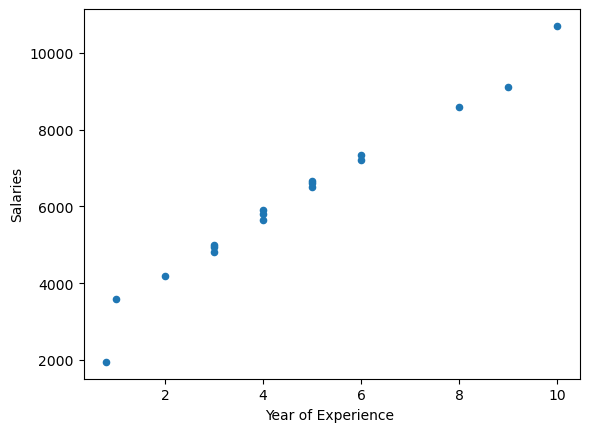

In [40]:
df.plot(kind='scatter',x='Year of Experience ',y='Salaries')#scatter plot visuals

In [41]:
#defining the dependent and independent variables
x=df[['Year of Experience ']]
y=df['Salaries']

In [42]:
#split proportion
x_train,x_test,y_train,y_test= train_test_split(x ,y, test_size=0.2 , random_state=0)

In [43]:
#split dimension
x_train.shape

(13, 1)

In [44]:
#call on linear regression model
model=LinearRegression()

In [45]:
#ttraining the model
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [46]:
#testing the model
y_pred=model.predict(x_test)

In [47]:
#co-efficient of determination from model
model.score(x_test,y_test)

0.9388188248632916

In [48]:
#co-efficient of determination from sklearn.metrics
r2=r2_score(y_test,y_pred)
r2

0.9388188248632916

In [49]:
#PERFORMANCE EVALUATION
#MSE evaluation
mse=mean_squared_error(y_test,y_pred)
print(mse)

137389.97641637074


In [50]:
#MAE evaluation
mae=mean_absolute_error(y_test,y_pred)
print(mae)

225.50295968829641


In [51]:
#visualizing a heatmap

In [52]:
#111
corr=df.corr()

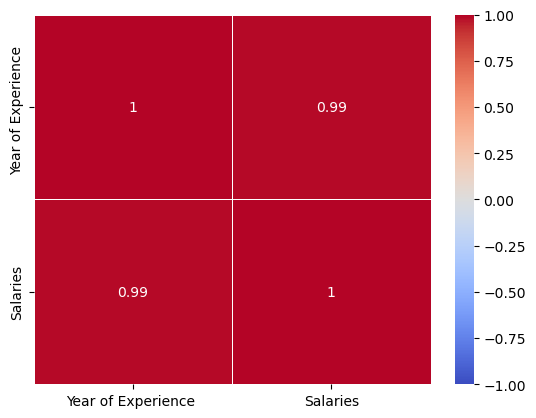

In [53]:
h=sns.heatmap(corr,cmap='coolwarm',annot=True, vmin=-1,vmax=1,linewidths=0.55)

In [54]:
#renaming columns specified
ndf=df.rename(columns={'Year of Experience ':'EXP-Y','Salaries':'Pay'})
ndf

,EXP-Y,Pay
0,3.0,5000
1,5.0,6500
2,6.0,7200
3,4.0,5800
4,10.0,10700
5,8.0,8600
6,6.0,7350
7,4.0,5900
8,3.0,4950
9,9.0,9100


In [55]:
#Renaming all columns at once
df.columns=['YYYY','Money']
df

,YYYY,Money
0,3.0,5000
1,5.0,6500
2,6.0,7200
3,4.0,5800
4,10.0,10700
5,8.0,8600
6,6.0,7350
7,4.0,5900
8,3.0,4950
9,9.0,9100


# Decision Tree Regressor

In [56]:
dec=DecisionTreeRegressor(random_state=42)

In [57]:
dec.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [58]:
dec.predict(x_test)

array([6625., 7200., 4900., 8600.])

In [59]:
dec.score(x_test,y_test)

0.9676454216532145

In [60]:
r2_score(y_test,y_pred)

0.9388188248632916

In [61]:
dec.predict([[10]])

C:\Users\PATHWAY\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


array([10700.])

# Random Forest Regressor

In [62]:
rand=RandomForestRegressor(random_state=42)

In [63]:
rand.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [64]:
rand.predict(x_test)

array([6530.675     , 7026.625     , 4873.55833333, 8981.58333333])

In [65]:
rand.predict([[10]])

C:\Users\PATHWAY\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


array([9611.58333333])

In [66]:
rand.score(x_test,y_test)

0.9860419502814114